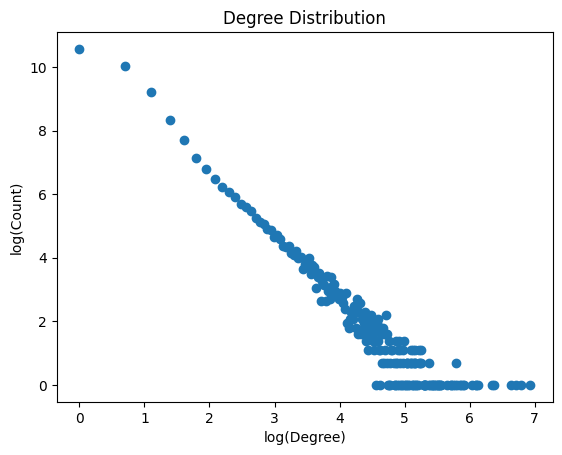

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
import math

# Load and filter the data
def load_and_filter_data(filename):
    with open(filename, 'r') as f:
        lines = f.readlines()
    return [line for line in lines if is_valid_year(line)]

# check if the year is valid and within the desired range
def is_valid_year(line):
    try:
        year = int(line.split()[0])
        return 1985 <= year <= 2005
    except ValueError:
        return False

# Create a coauthorship graph
def create_coauthorship_graph(data):
    G = nx.Graph()
    for line in data:
        add_edges_from_authors(G, line)
    return G

# Add edges between coauthors in the graph
def add_edges_from_authors(G, line):
    authors = line.split(',')[0].split('&')
    authors = [author.strip() for author in authors]
    for i in range(len(authors)):
        for j in range(i + 1, len(authors)):
            G.add_edge(authors[i], authors[j])

def write_degree_distribution(degree_count, netid):
    with open('hw1solution.txt', 'w') as f:
        f.write(f'@ {netid}\n')
        for degree, count in sorted(degree_count.items()):
            f.write(f'@ 1 {degree} {count}\n')

# Calculate and plot the degree distribution
def calculate_and_plot_degree_distribution(G, plot_filename):
    degree_count = calculate_degree_counts(G)
    write_degree_distribution(degree_count, 'xc535')
    plot_degree_distribution(degree_count, plot_filename)

# Calculate the degree counts for the graph
def calculate_degree_counts(G):
    degree_count = {}
    for _, degree in G.degree():
        degree_count[degree] = degree_count.get(degree, 0) + 1
    return degree_count

# Plot the degree distribution
def plot_degree_distribution(degree_count, plot_filename):
    x = [math.log(d) for d in degree_count if d > 0]
    y = [math.log(degree_count[d]) for d in degree_count if d > 0]
    plt.scatter(x, y)
    plt.xlabel('log(Degree)')
    plt.ylabel('log(Count)')
    plt.title('Degree Distribution')
    plt.savefig(plot_filename)

# for Problem 1
data = load_and_filter_data('ps1data.txt')
G = create_coauthorship_graph(data)
calculate_and_plot_degree_distribution(G, 'plot1.pdf')

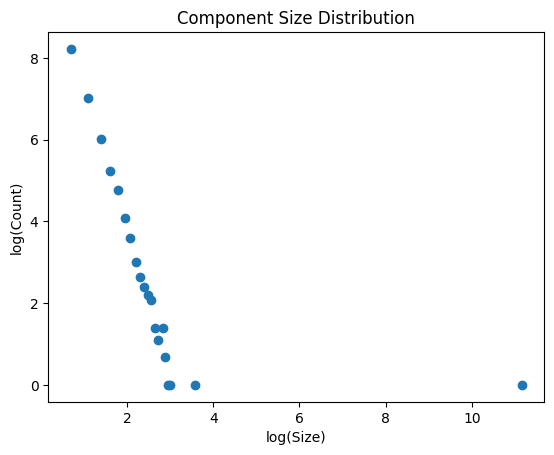

In [6]:
# Function to find connected components
def find_connected_components(G):
    components = [len(c) for c in nx.connected_components(G)]
    return components

# Function to plot component sizes
def plot_component_sizes(component_sizes, plot_filename):
    size_count = {}
    for size in component_sizes:
        size_count[size] = size_count.get(size, 0) + 1

    x = [math.log(s) for s in size_count if s > 1]
    y = [math.log(size_count[s]) for s in size_count if s > 1]

    plt.scatter(x, y)
    plt.xlabel('log(Size)')
    plt.ylabel('log(Count)')
    plt.title('Component Size Distribution')
    plt.savefig(plot_filename)

# Execution for Problem 2
component_sizes = find_connected_components(G)
largest_component_size = max(component_sizes)
total_nodes = G.number_of_nodes()
ratio = largest_component_size / total_nodes

# Write output
with open('hw1solution.txt', 'a') as f:
    f.write(f'@ 2 {largest_component_size} {total_nodes} {ratio}\n')

plot_component_sizes(component_sizes, 'plot2.pdf')

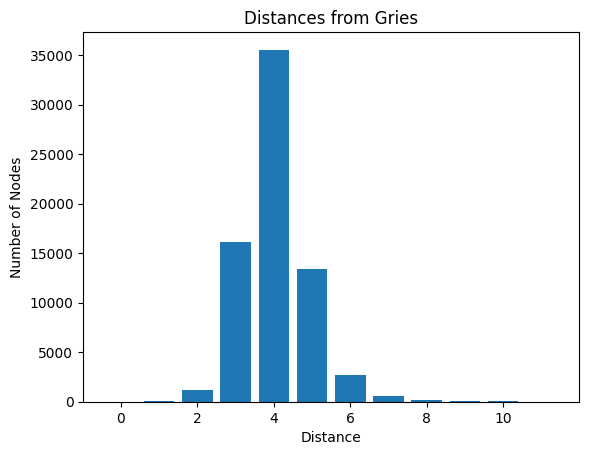

In [7]:
# Function to calculate node-to-node distances from Gries
def calculate_distances_from_node(G, root_node):
    distances = nx.single_source_shortest_path_length(G, root_node)
    max_distance = max(distances.values())
    distance_counts = [0] * (max_distance + 1)
    for dist in distances.values():
        distance_counts[dist] += 1
    return distance_counts

# Function to plot distances
def plot_distances(distance_counts, plot_filename):
    plt.bar(range(len(distance_counts)), distance_counts)
    plt.xlabel('Distance')
    plt.ylabel('Number of Nodes')
    plt.title('Distances from Gries')
    plt.savefig(plot_filename)

# Execution for Problem 3
distance_counts = calculate_distances_from_node(G, 'Gries')
with open('hw1solution.txt', 'a') as f:
    for j, count in enumerate(distance_counts):
        f.write(f'@ 3 {j} {count}\n')

plot_distances(distance_counts, 'plot3.pdf')

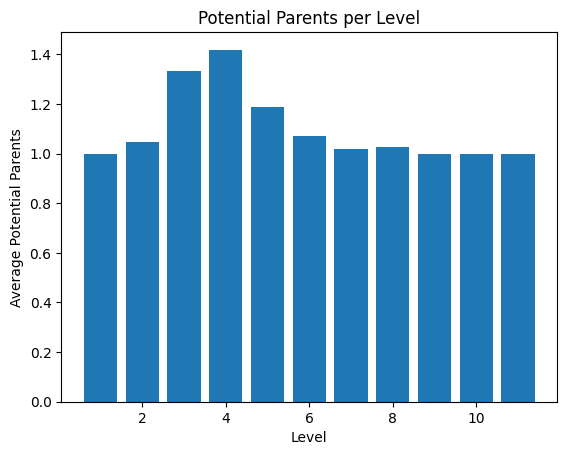

In [8]:
# Function to calculate potential parents in BFS tree
def calculate_potential_parents(G, root_node):
    bfs_tree = nx.bfs_tree(G, root_node)
    levels = nx.single_source_shortest_path_length(bfs_tree, root_node)
    max_level = max(levels.values())
    potential_parents = []

    for level in range(1, max_level + 1):
        nodes_at_level = [node for node, lvl in levels.items() if lvl == level]
        avg_parents = sum(len([nbr for nbr in G.neighbors(node) if levels.get(nbr, -1) == level - 1]) for node in nodes_at_level) / len(nodes_at_level)
        potential_parents.append(avg_parents)

    return potential_parents

# Function to plot potential parents
def plot_potential_parents(potential_parents, plot_filename):
    plt.bar(range(1, len(potential_parents) + 1), potential_parents)
    plt.xlabel('Level')
    plt.ylabel('Average Potential Parents')
    plt.title('Potential Parents per Level')
    plt.savefig(plot_filename)

# Execution for Problem 4
potential_parents = calculate_potential_parents(G, 'Gries')
with open('hw1solution.txt', 'a') as f:
    for j, p in enumerate(potential_parents, start=1):
        f.write(f'@ 4 {j} {p}\n')

plot_potential_parents(potential_parents, 'plot4.pdf')